In [7]:
import pandas as pd
import numpy as np

# Load dataset
df = pd.read_csv("../data/customer_churn.csv")

# Display basic information
print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [9]:
print(df["Churn"].value_counts())

print("\nChurn Percentage:")
print(df["Churn"].value_counts(normalize=True) * 100)

Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn Percentage:
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


In [12]:
# Check missing values
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [13]:
# Check duplicate records
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 0


In [14]:
# Check blank/space values in TotalCharges
print("Blank TotalCharges:")
print((df["TotalCharges"].astype(str).str.strip() == "").sum())

Blank TotalCharges:
11


In [19]:
# Check unique values in TotalCharges
print("Sample TotalCharges values:")
print(df["TotalCharges"].head(20).tolist())

Sample TotalCharges values:
['29.85', '1889.5', '108.15', '1840.75', '151.65', '820.5', '1949.4', '301.9', '3046.05', '3487.95', '587.45', '326.8', '5681.1', '5036.3', '2686.05', '7895.15', '1022.95', '7382.25', '528.35', '1862.9']


In [20]:
df[["SeniorCitizen", "tenure", "MonthlyCharges"]].describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [23]:
df["TotalCharges"].describe()

count     7043
unique    6531
top           
freq        11
Name: TotalCharges, dtype: object

In [24]:
categorical_columns = df.select_dtypes(include="object").columns

for column in categorical_columns:
    print(f"\n{column}:")
    print(df[column].value_counts())


customerID:
customerID
7590-VHVEG    1
3791-LGQCY    1
6008-NAIXK    1
5956-YHHRX    1
5365-LLFYV    1
             ..
9796-MVYXX    1
2637-FKFSY    1
1552-AAGRX    1
4304-TSPVK    1
3186-AJIEK    1
Name: count, Length: 7043, dtype: int64

gender:
gender
Male      3555
Female    3488
Name: count, dtype: int64

Partner:
Partner
No     3641
Yes    3402
Name: count, dtype: int64

Dependents:
Dependents
No     4933
Yes    2110
Name: count, dtype: int64

PhoneService:
PhoneService
Yes    6361
No      682
Name: count, dtype: int64

MultipleLines:
MultipleLines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64

InternetService:
InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

OnlineSecurity:
OnlineSecurity
No                     3498
Yes                    2019
No internet service    1526
Name: count, dtype: int64

OnlineBackup:
OnlineBackup
No                     3088
Yes                

In [27]:
# Create a copy of the original dataset
df_clean = df.copy()

# Convert TotalCharges to numeric
# Invalid/blank values will become NaN
df_clean["TotalCharges"] = pd.to_numeric(
    df_clean["TotalCharges"],
    errors="coerce"
)

# Check how many NaN values were created
print("Missing TotalCharges after conversion:")
print(df_clean["TotalCharges"].isnull().sum())

Missing TotalCharges after conversion:
11


In [29]:
# Fill missing TotalCharges with 0
df_clean["TotalCharges"] = df_clean["TotalCharges"].fillna(0)

print("Missing TotalCharges after cleaning:")
print(df_clean["TotalCharges"].isnull().sum())

Missing TotalCharges after cleaning:
0


In [31]:
print(df_clean.dtypes)

customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
Churn                object
dtype: object


In [32]:
print(df_clean.shape)

(7043, 21)


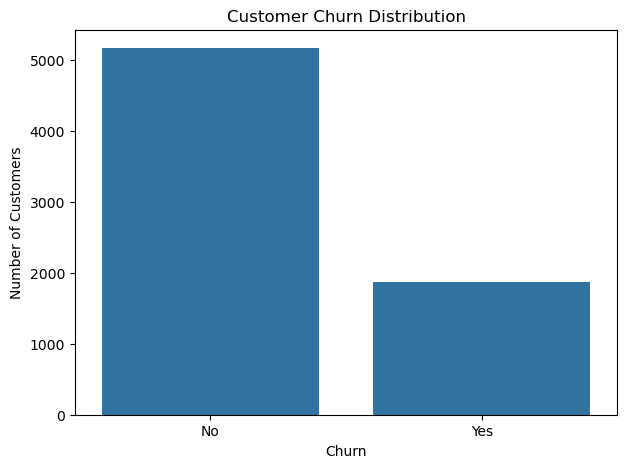

In [35]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df_clean,
    x="Churn"
)

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

plt.show()

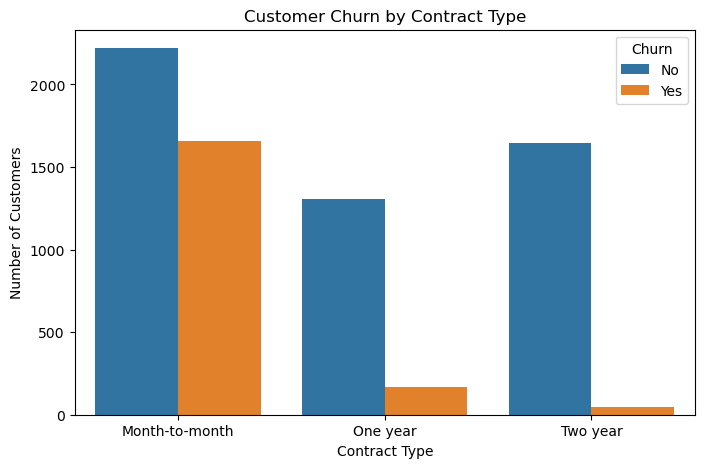

In [36]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_clean,
    x="Contract",
    hue="Churn"
)

plt.title("Customer Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")

plt.show()

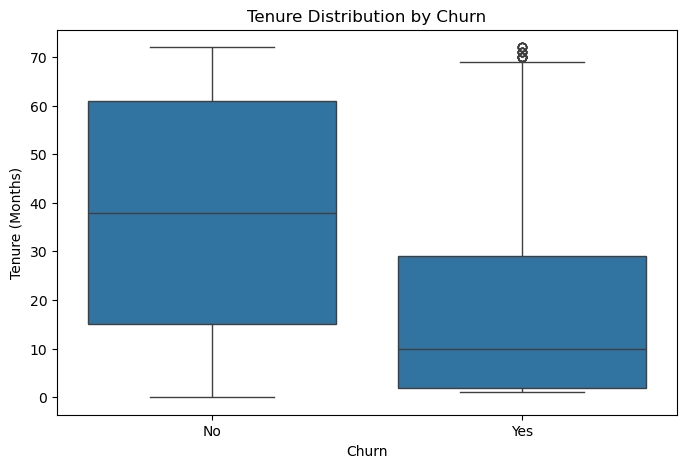

In [37]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_clean,
    x="Churn",
    y="tenure"
)

plt.title("Tenure Distribution by Churn")
plt.xlabel("Churn")
plt.ylabel("Tenure (Months)")

plt.show()

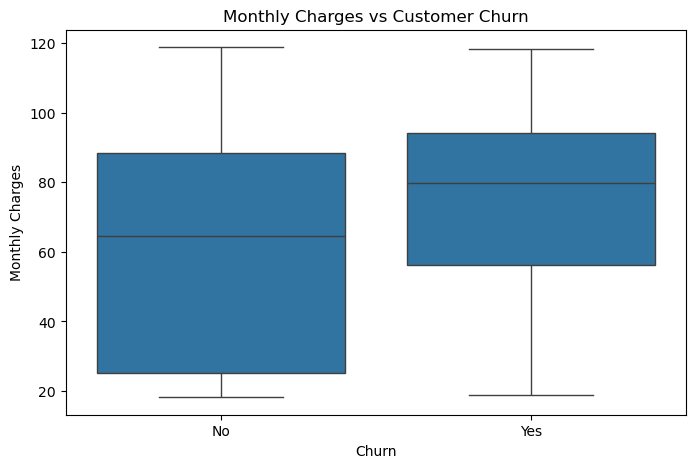

In [38]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_clean,
    x="Churn",
    y="MonthlyCharges"
)

plt.title("Monthly Charges vs Customer Churn")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")

plt.show()

In [39]:
contract_churn = pd.crosstab(
    df_clean["Contract"],
    df_clean["Churn"],
    normalize="index"
) * 100

print(contract_churn.round(2))

Churn              No    Yes
Contract                    
Month-to-month  57.29  42.71
One year        88.73  11.27
Two year        97.17   2.83


In [40]:
internet_churn = pd.crosstab(
    df_clean["InternetService"],
    df_clean["Churn"],
    normalize="index"
) * 100

print(internet_churn.round(2))

Churn               No    Yes
InternetService              
DSL              81.04  18.96
Fiber optic      58.11  41.89
No               92.60   7.40


In [41]:
payment_churn = pd.crosstab(
    df_clean["PaymentMethod"],
    df_clean["Churn"],
    normalize="index"
) * 100

print(payment_churn.round(2))

Churn                         No    Yes
PaymentMethod                          
Bank transfer (automatic)  83.29  16.71
Credit card (automatic)    84.76  15.24
Electronic check           54.71  45.29
Mailed check               80.89  19.11


In [42]:
df_model = df_clean.copy()

df_model["Churn"] = df_model["Churn"].map({
    "No": 0,
    "Yes": 1
})

print(df_model["Churn"].value_counts())

Churn
0    5174
1    1869
Name: count, dtype: int64


In [43]:
print("Original dataset:", df.shape)
print("Cleaned dataset:", df_clean.shape)

print("\nTarget distribution:")
print(df_clean["Churn"].value_counts())

Original dataset: (7043, 21)
Cleaned dataset: (7043, 21)

Target distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [174]:
try:
    import xgboost
    print("XGBoost version:", xgboost.__version__)
except ImportError:
    print("XGBoost is not installed")

try:
    import lightgbm
    print("LightGBM version:", lightgbm.__version__)
except ImportError:
    print("LightGBM is not installed")

XGBoostError: 
XGBoost Library (libxgboost.dylib) could not be loaded.
Likely causes:
  * OpenMP runtime is not installed
    - vcomp140.dll or libgomp-1.dll for Windows
    - libomp.dylib for Mac OSX
    - libgomp.so for Linux and other UNIX-like OSes
    Mac OSX users: Run `brew install libomp` to install OpenMP runtime.

  * You are running 32-bit Python on a 64-bit OS

Error message(s): ['dlopen(/opt/anaconda3/lib/python3.12/site-packages/xgboost/lib/libxgboost.dylib, 0x0006): Symbol not found: ___kmpc_dispatch_deinit\n  Referenced from: <77F13E08-27C4-30BB-B9B6-08064A31C57F> /opt/anaconda3/lib/python3.12/site-packages/xgboost/lib/libxgboost.dylib\n  Expected in:     <8AE74FFC-75EE-374B-BA46-A70944EA81BD> /opt/anaconda3/lib/libomp.dylib']


In [ ]:
python -m pip install xgboost lightgbm scikit-learn

In [ ]:

%pip install xgboost lightgbm scikit-learn


In [1]:

import xgboost
import lightgbm
import sklearn

print("XGBoost version:", xgboost.__version__)
print("LightGBM version:", lightgbm.__version__)
print("Scikit-learn version:", sklearn.__version__)


XGBoostError: 
XGBoost Library (libxgboost.dylib) could not be loaded.
Likely causes:
  * OpenMP runtime is not installed
    - vcomp140.dll or libgomp-1.dll for Windows
    - libomp.dylib for Mac OSX
    - libgomp.so for Linux and other UNIX-like OSes
    Mac OSX users: Run `brew install libomp` to install OpenMP runtime.

  * You are running 32-bit Python on a 64-bit OS

Error message(s): ['dlopen(/opt/anaconda3/lib/python3.12/site-packages/xgboost/lib/libxgboost.dylib, 0x0006): Symbol not found: ___kmpc_dispatch_deinit\n  Referenced from: <77F13E08-27C4-30BB-B9B6-08064A31C57F> /opt/anaconda3/lib/python3.12/site-packages/xgboost/lib/libxgboost.dylib\n  Expected in:     <8AE74FFC-75EE-374B-BA46-A70944EA81BD> /opt/anaconda3/lib/libomp.dylib']


In [3]:
import sys
print(sys.executable)
print(sys.version)

/opt/anaconda3/bin/python
3.12.4 | packaged by Anaconda, Inc. | (main, Jun 18 2024, 10:14:12) [Clang 14.0.6 ]


In [53]:

import sklearn
import pandas as pd

print("Scikit-learn version:", sklearn.__version__)
print("Dataset shape:", df_clean.shape)
print(df_clean["Churn"].value_counts())


Scikit-learn version: 1.4.2
Dataset shape: (7043, 21)
Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [55]:

# Step 2: Prepare Data for Machine Learning

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report, confusion_matrix
)

# Copy cleaned dataset
model_df = df_clean.copy()

# Convert target into binary values
model_df["Churn"] = model_df["Churn"].map({"No": 0, "Yes": 1})

# Remove customerID because it is an identifier, not a useful feature
X = model_df.drop(columns=["Churn", "customerID"])
y = model_df["Churn"]

# Identify numeric and categorical columns
numeric_features = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_features = X.select_dtypes(include=["object", "category"]).columns.tolist()

# Preprocess numeric and categorical data
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# Split data: 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)
print("Numeric features:", len(numeric_features))
print("Categorical features:", len(categorical_features))
print("\nData preparation completed successfully!")


Training data shape: (5634, 19)
Testing data shape: (1409, 19)
Numeric features: 4
Categorical features: 15

Data preparation completed successfully!


In [60]:

# Step 3: Train and Evaluate Machine Learning Models

from sklearn.base import clone

# Define models
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )
}

results = []
trained_models = {}

for name, model in models.items():
    # Create an independent preprocessing pipeline for each model
    clf = Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("classifier", model)
    ])

    # Train model
    clf.fit(X_train, y_train)

    # Predict on test data
    y_pred = clf.predict(X_test)

    # Evaluate model
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, y_pred, zero_division=0
        )
    })

    trained_models[name] = clf

# Display comparison
results_df = pd.DataFrame(results)
print("Model Performance Comparison:")
display(results_df.round(4))

# Detailed classification report
for name, clf in trained_models.items():
    print(f"\n{'=' * 50}")
    print(name)
    print("=" * 50)

    predictions = clf.predict(X_test)
    print(classification_report(
        y_test,
        predictions,
        target_names=["No Churn", "Churn"],
        zero_division=0
    ))

    print("Confusion Matrix:")
    print(confusion_matrix(y_test, predictions))


/opt/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Model Performance Comparison:


,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.7395,0.5060,0.7861,0.6157
1,Random Forest,0.7821,0.6167,0.4733,0.5356



Logistic Regression
              precision    recall  f1-score   support

    No Churn       0.90      0.72      0.80      1035
       Churn       0.51      0.79      0.62       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409

Confusion Matrix:
[[748 287]
 [ 80 294]]

Random Forest
              precision    recall  f1-score   support

    No Churn       0.82      0.89      0.86      1035
       Churn       0.62      0.47      0.54       374

    accuracy                           0.78      1409
   macro avg       0.72      0.68      0.70      1409
weighted avg       0.77      0.78      0.77      1409

Confusion Matrix:
[[925 110]
 [197 177]]


In [62]:

# Step 4: Tune the Logistic Regression Threshold

import numpy as np
from sklearn.base import clone
from sklearn.model_selection import train_test_split

# Split training data into fitting and validation sets
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

# Create Logistic Regression pipeline
lr_model = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

# Train using fitting data only
lr_model.fit(X_fit, y_fit)

# Get churn probabilities on validation data
val_probabilities = lr_model.predict_proba(X_val)[:, 1]

# Compare candidate thresholds
threshold_results = []

for threshold in np.arange(0.20, 0.71, 0.05):
    val_predictions = (
        val_probabilities >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": round(float(threshold), 2),
        "Precision": precision_score(
            y_val, val_predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, val_predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_val, val_predictions, zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)

print("Validation Threshold Comparison:")
display(threshold_df.round(4))

# Select threshold with the highest validation F1 score
best_threshold = threshold_df.loc[
    threshold_df["F1 Score"].idxmax(), "Threshold"
]

print("Selected threshold:", best_threshold)

# Retrain on the complete training set
final_model = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

final_model.fit(X_train, y_train)

# Final evaluation on untouched test data
test_probabilities = final_model.predict_proba(X_test)[:, 1]
final_predictions = (
    test_probabilities >= best_threshold
).astype(int)

print("\nFinal Test Results:")
print("Threshold:", best_threshold)
print("Accuracy:", round(
    accuracy_score(y_test, final_predictions), 4
))
print("Precision:", round(
    precision_score(y_test, final_predictions, zero_division=0), 4
))
print("Recall:", round(
    recall_score(y_test, final_predictions, zero_division=0), 4
))
print("F1 Score:", round(
    f1_score(y_test, final_predictions, zero_division=0), 4
))

print("\nClassification Report:")
print(classification_report(
    y_test,
    final_predictions,
    target_names=["No Churn", "Churn"],
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, final_predictions))


Validation Threshold Comparison:


/opt/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,Threshold,Precision,Recall,F1 Score
0,0.20,0.3835,0.9465,0.5458
1,0.25,0.3989,0.9298,0.5582
2,0.30,0.4209,0.9164,0.5768
3,0.35,0.4370,0.8930,0.5868
4,0.40,0.4643,0.8696,0.6054
5,0.45,0.4911,0.8261,0.6160
6,0.50,0.5241,0.7993,0.6331
7,0.55,0.5485,0.7559,0.6357
8,0.60,0.5730,0.7090,0.6338
9,0.65,0.6168,0.6622,0.6387


Selected threshold: 0.65

Final Test Results:
Threshold: 0.65
Accuracy: 0.7771
Precision: 0.5682
Recall: 0.6684
F1 Score: 0.6143

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.87      0.82      0.84      1035
       Churn       0.57      0.67      0.61       374

    accuracy                           0.78      1409
   macro avg       0.72      0.74      0.73      1409
weighted avg       0.79      0.78      0.78      1409

Confusion Matrix:
[[845 190]
 [124 250]]


/opt/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [64]:

# Step 5: Improve Logistic Regression and fix convergence

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score
)

# Create an improved numeric preprocessing pipeline
numeric_transformer_scaled = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer_scaled = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor_scaled = ColumnTransformer(transformers=[
    ("num", numeric_transformer_scaled, numeric_features),
    ("cat", categorical_transformer_scaled, categorical_features)
])

# Separate validation data from training data
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

# Train on the fitting subset
validation_model = Pipeline(steps=[
    ("preprocessor", clone(preprocessor_scaled)),
    ("classifier", LogisticRegression(
        max_iter=5000,
        class_weight="balanced",
        random_state=42
    ))
])

validation_model.fit(X_fit, y_fit)

# Choose threshold using validation F1 score
val_probs = validation_model.predict_proba(X_val)[:, 1]

threshold_scores = []

for threshold in np.arange(0.20, 0.71, 0.05):
    preds = (val_probs >= threshold).astype(int)

    threshold_scores.append({
        "Threshold": round(float(threshold), 2),
        "Precision": precision_score(
            y_val, preds, zero_division=0
        ),
        "Recall": recall_score(
            y_val, preds, zero_division=0
        ),
        "F1 Score": f1_score(
            y_val, preds, zero_division=0
        )
    })

threshold_results_scaled = pd.DataFrame(threshold_scores)
display(threshold_results_scaled.round(4))

best_threshold = float(
    threshold_results_scaled.loc[
        threshold_results_scaled["F1 Score"].idxmax(),
        "Threshold"
    ]
)

print("Best validation threshold:", best_threshold)

# Train final model on all training data
final_model = Pipeline(steps=[
    ("preprocessor", clone(preprocessor_scaled)),
    ("classifier", LogisticRegression(
        max_iter=5000,
        class_weight="balanced",
        random_state=42
    ))
])

final_model.fit(X_train, y_train)

# Evaluate once on the test set
test_probs = final_model.predict_proba(X_test)[:, 1]
final_predictions = (test_probs >= best_threshold).astype(int)

print("\nFinal Test Results")
print("Accuracy:", round(
    accuracy_score(y_test, final_predictions), 4
))
print("Precision:", round(
    precision_score(y_test, final_predictions, zero_division=0), 4
))
print("Recall:", round(
    recall_score(y_test, final_predictions, zero_division=0), 4
))
print("F1 Score:", round(
    f1_score(y_test, final_predictions, zero_division=0), 4
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, final_predictions))


,Threshold,Precision,Recall,F1 Score
0,0.20,0.3835,0.9465,0.5458
1,0.25,0.3977,0.9298,0.5571
2,0.30,0.4228,0.9164,0.5787
3,0.35,0.4370,0.8930,0.5868
4,0.40,0.4642,0.8662,0.6044
5,0.45,0.4920,0.8261,0.6167
6,0.50,0.5241,0.7993,0.6331
7,0.55,0.5459,0.7559,0.6339
8,0.60,0.5730,0.7090,0.6338
9,0.65,0.6180,0.6656,0.6409


Best validation threshold: 0.65

Final Test Results
Accuracy: 0.7771
Precision: 0.5682
Recall: 0.6684
F1 Score: 0.6143

Confusion Matrix:
[[845 190]
 [124 250]]


In [66]:

# Step 6: Save the final trained model

import joblib
import os

# Save model and threshold together
model_artifact = {
    "model": final_model,
    "threshold": best_threshold,
    "features": X_train.columns.tolist()
}

joblib.dump(model_artifact, "customer_churn_model.pkl")

print("Model saved successfully!")
print("File:", os.path.abspath("customer_churn_model.pkl"))
print("Selected threshold:", best_threshold)


Model saved successfully!
File: /Users/neelshekharsingh/CustomerChurnPrediction/notebooks/customer_churn_model.pkl
Selected threshold: 0.65


In [68]:

# Step 7: Test a prediction using an existing customer record

saved_artifact = joblib.load("customer_churn_model.pkl")

saved_model = saved_artifact["model"]
threshold = saved_artifact["threshold"]

# Use one record from the test dataset
sample_customer = X_test.iloc[[0]]

probability = saved_model.predict_proba(sample_customer)[0, 1]
prediction = int(probability >= threshold)

print("Churn Probability:", f"{probability:.2%}")
print("Prediction:", "Will Churn" if prediction == 1 else "Will Not Churn")


Churn Probability: 11.77%
Prediction: Will Not Churn


In [70]:

%pip install streamlit joblib


Note: you may need to restart the kernel to use updated packages.


In [72]:
import os
print(os.path.abspath("customer_churn_model.pkl"))

/Users/neelshekharsingh/CustomerChurnPrediction/notebooks/customer_churn_model.pkl


In [74]:

# Save the input fields required by the Streamlit app

import joblib
import pandas as pd

# Use the same features used during model training
feature_df = X_train.copy()

schema = {}

for col in feature_df.columns:
    if pd.api.types.is_numeric_dtype(feature_df[col]):
        schema[col] = {
            "type": "numeric",
            "min": float(feature_df[col].min()),
            "max": float(feature_df[col].max()),
            "default": float(feature_df[col].median()),
            "integer": pd.api.types.is_integer_dtype(feature_df[col])
        }
    else:
        options = sorted(
            feature_df[col].dropna().astype(str).unique().tolist()
        )

        mode_values = feature_df[col].dropna().mode()
        default_value = (
            str(mode_values.iloc[0]) if not mode_values.empty
            else options[0]
        )

        schema[col] = {
            "type": "categorical",
            "options": options,
            "default": default_value
        }

joblib.dump(schema, "customer_churn_schema.pkl")

print("Input schema saved successfully!")
print("Features:", len(schema))
print("Schema file:", __import__("os").path.abspath(
    "customer_churn_schema.pkl"
))



Input schema saved successfully!
Features: 19
Schema file: /Users/neelshekharsingh/CustomerChurnPrediction/notebooks/customer_churn_schema.pkl


In [76]:

import os

print("Current folder:", os.getcwd())
print("\nFiles in this folder:")

for file in os.listdir():
    print(file)


Current folder: /Users/neelshekharsingh/CustomerChurnPrediction/notebooks

Files in this folder:
customer_churn_model.pkl
customer_churn_schema.pkl
.ipynb_checkpoints
01_data_analysis.ipynb


In [78]:

from pathlib import Path

project_dir = Path("/Users/neelshekharsingh/CustomerChurnPrediction")
app_path = project_dir / "app.py"

print("Project folder exists:", project_dir.exists())
print("App file path:", app_path)
print("App file already exists:", app_path.exists())


Project folder exists: True
App file path: /Users/neelshekharsingh/CustomerChurnPrediction/app.py
App file already exists: True


In [84]:

from pathlib import Path

app_path = Path(
    "/Users/neelshekharsingh/CustomerChurnPrediction/app.py"
)

print(app_path.read_text())


In [86]:

from pathlib import Path

app_path = Path(
    "/Users/neelshekharsingh/CustomerChurnPrediction/app.py"
)

print("File exists:", app_path.exists())
print("File size:", app_path.stat().st_size, "bytes")

content = app_path.read_text()
print("\nFile content:")
print(repr(content[:1000]))


File exists: True
File size: 0 bytes

File content:
''


In [88]:

from pathlib import Path

app_path = Path("/Users/neelshekharsingh/CustomerChurnPrediction/app.py")

app_code = r'''
import os
import joblib
import pandas as pd
import streamlit as st

BASE_DIR = os.path.dirname(os.path.abspath(__file__))
MODEL_PATH = os.path.join(
    BASE_DIR, "notebooks", "customer_churn_model.pkl"
)
SCHEMA_PATH = os.path.join(
    BASE_DIR, "notebooks", "customer_churn_schema.pkl"
)

st.set_page_config(
    page_title="Customer Churn Prediction",
    page_icon="📊",
    layout="wide"
)

st.title("📊 Customer Churn Prediction")
st.write(
    "Customer ki details bharo aur predict karo ki customer "
    "service chhod sakta hai ya nahi."
)

@st.cache_resource
def load_artifacts():
    model_data = joblib.load(MODEL_PATH)
    schema_data = joblib.load(SCHEMA_PATH)
    return model_data, schema_data

try:
    if not os.path.exists(MODEL_PATH):
        st.error(f"Model file nahi mili: {MODEL_PATH}")
        st.stop()

    if not os.path.exists(SCHEMA_PATH):
        st.error(f"Schema file nahi mili: {SCHEMA_PATH}")
        st.stop()

    model_data, schema = load_artifacts()
    model = model_data["model"]
    threshold = float(model_data["threshold"])

except Exception as e:
    st.error(f"Model load karne mein problem: {e}")
    st.stop()

st.subheader("Customer Details")

with st.form("customer_form"):
    customer_data = {}
    columns = st.columns(2)

    for i, (feature, info) in enumerate(schema.items()):
        with columns[i % 2]:
            if info["type"] == "numeric":
                minimum = float(info["min"])
                maximum = float(info["max"])
                default = float(info["default"])

                if minimum == maximum:
                    customer_data[feature] = minimum
                else:
                    customer_data[feature] = st.number_input(
                        feature,
                        min_value=minimum,
                        max_value=maximum,
                        value=min(max(default, minimum), maximum),
                        step=1.0 if info.get("integer", False) else 0.1
                    )
            else:
                options = info.get("options", [])
                default = info.get("default")

                if not options:
                    customer_data[feature] = st.text_input(feature)
                else:
                    index = options.index(default) if default in options else 0
                    customer_data[feature] = st.selectbox(
                        feature,
                        options,
                        index=index
                    )

    submitted = st.form_submit_button(
        "Predict Churn",
        type="primary"
    )

if submitted:
    customer_df = pd.DataFrame(
        [customer_data],
        columns=list(schema.keys())
    )

    try:
        probability = float(model.predict_proba(customer_df)[0, 1])
        prediction = int(probability >= threshold)

        st.divider()
        st.subheader("Prediction Result")

        col1, col2 = st.columns(2)
        col1.metric("Churn Probability", f"{probability:.2%}")
        col2.metric("Decision Threshold", f"{threshold:.2f}")

        if prediction == 1:
            st.error("⚠️ Customer may churn (leave the service).")
        else:
            st.success("✅ Customer is predicted not to churn.")

        st.caption(
            "Prediction is based on the trained machine-learning model. "
            "It is an estimate, not a guarantee."
        )

    except Exception as e:
        st.error(f"Prediction mein problem: {e}")
'''

app_path.write_text(app_code, encoding="utf-8")

print("App file written:", app_path.exists())
print("File size:", app_path.stat().st_size, "bytes")


App file written: True
File size: 3481 bytes
